In [ ]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv

load_dotenv()

model = ChatGroq(model_name="openai/gpt-oss-20b")

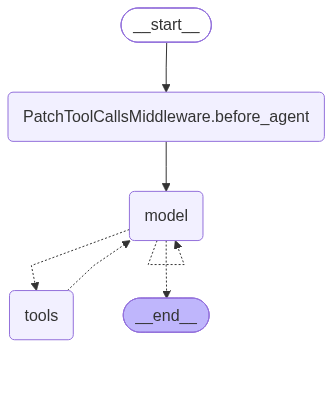

In [43]:
from langgraph.store.memory import InMemoryStore
from deepagents import create_deep_agent
from deepagents.backends import StoreBackend


store = InMemoryStore()

backend = StoreBackend(
    namespace= lambda _rt: ("deepagents_root", _rt.context["user_id"]),
    store=store
)

agent = create_deep_agent(
    model = "groq:openai/gpt-oss-20b",
    backend=backend,
)
agent

In [ ]:
agent.invoke({
    "messages":{
        "role": "user",
        "content": "create"
    }
},{
    "configurable":{
        "thread_id": 1,
        "user_id": 1
    }
})

{'messages': [HumanMessage(content='test', additional_kwargs={}, response_metadata={}, id='5a0e66e3-8836-4c95-8dbf-a8c461d64a52'),
  AIMessage(content='Sure thing! What would you like to test? If you need me to list files, read a specific file, or run a small task, just let me know.', additional_kwargs={'reasoning_content': 'The user says "test". Likely they want to test the system. Maybe they want to see the file structure or something. We need to respond appropriately. The user just said "test". We might ask what they want to test. Or we can just respond acknowledging. Probably best to ask for clarification.'}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 1903, 'total_tokens': 2009, 'completion_time': 0.110805717, 'completion_tokens_details': {'reasoning_tokens': 63}, 'prompt_time': 0.157978764, 'prompt_tokens_details': None, 'queue_time': 0.306553192, 'total_time': 0.268784481}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c9afb2bdb4

In [60]:
from typing import Dict, Any 

def chat(agent, query: str, thread_id: int, user_id: int | None= None)->Dict[str, Any]:
    return agent.invoke({
            "messages":[{
                "role": "user",
                "content": query
            }]
        },
        config = {
            "configurable":{
                "thread_id": thread_id,
                "user_id": str(user_id or thread_id)
            }
        },
        context = {
            "user_id": str(user_id or thread_id)
        })



In [54]:
res = chat(agent=agent, 
    query="create a file notes.txt in notes folder and write a content:- 1. AI Engineer 2. Software Engineer 3. Data Scientist",
    thread_id=1,
    user_id=1)
res

{'messages': [HumanMessage(content='create a file notes.txt in notes folder and write a content:- 1. AI Engineer 2. Software Engineer 3. Data Scientist', additional_kwargs={}, response_metadata={}, id='38b0f5d3-969d-4787-a80d-c55698fc4b8c'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to create a file notes.txt in notes folder. First, check if notes folder exists. Let's list root.", 'tool_calls': [{'id': 'fc_a970fac3-d2dc-4db6-b487-d86fb8235500', 'function': {'arguments': '{"path":"/"}', 'name': 'ls'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 1930, 'total_tokens': 1978, 'completion_time': 0.051946026, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.122037178, 'prompt_tokens_details': None, 'queue_time': 0.308580128, 'total_time': 0.173983204}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_4a35f7bd1b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls',

In [57]:
res = chat(agent=agent, 
    query="read and provide the content of a file in notes folder",
    thread_id=2,
    user_id=1)
res

{'messages': [HumanMessage(content='read and provide the content of a file in notes folder', additional_kwargs={}, response_metadata={}, id='21efbf10-e9e8-4208-9ea4-be90fb320b72'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to read a file in notes folder. But user didn't specify file name. We need to list files. So first list directory.", 'tool_calls': [{'id': 'fc_0a1c19d7-33d1-4348-ba5f-943507db2b3b', 'function': {'arguments': '{"path":"/notes"}', 'name': 'ls'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 53, 'prompt_tokens': 1913, 'total_tokens': 1966, 'completion_time': 0.062666365, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.14001636, 'prompt_tokens_details': None, 'queue_time': 0.545360384, 'total_time': 0.202682725}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'gr

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5604.09it/s]


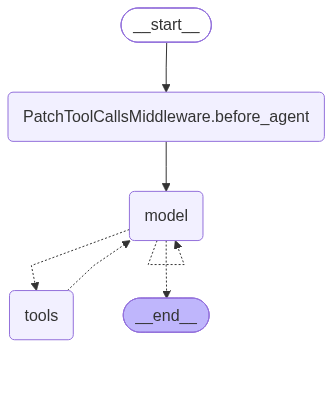

In [62]:
from langgraph.store.memory import InMemoryStore
from langchain.embeddings import init_embeddings
from deepagents.backends import StateBackend, StoreBackend, CompositeBackend
from deepagents import create_deep_agent


store = InMemoryStore(index={
"dims": 384,
"embed": init_embeddings("huggingface:sentence-transformers/all-MiniLM-L6-v2"),
"fields": ["text"],
})


shared_backend = StoreBackend(
    namespace= lambda run_time_obj: ("deep_root", run_time_obj.context.get("user_id", "default_user")),
    store=store
)

backend = CompositeBackend(
    default=StateBackend(),
    routes={
        "/shared/": shared_backend
    }
)

deep_agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=backend,
)

deep_agent

In [63]:
resp = chat(deep_agent, query="create a file test.txt in notes folder and add a small 5 line poem", thread_id=1, user_id=1)
resp

{'messages': [HumanMessage(content='create a file test.txt in notes folder and add a small 5 line poem', additional_kwargs={}, response_metadata={}, id='554bf2d9-4971-444c-98ac-a21cbba96c92'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to create a file test.txt in notes folder. We should check if notes folder exists. Use ls to list root.', 'tool_calls': [{'id': 'fc_b86fb43f-7ce9-4cec-ab8f-09e75c4fe469', 'function': {'arguments': '{"path":"/"}', 'name': 'ls'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 1918, 'total_tokens': 1968, 'completion_time': 0.055484403, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.114495303, 'prompt_tokens_details': None, 'queue_time': 0.40630136, 'total_time': 0.169979706}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}

In [64]:
resp["messages"][-1].content

"The file **`/shared/notes/test.txt`** has been created with the requested 5‑line poem:\n\n```\nA quiet dawn, the world anew\nThe sky whispers in soft hue\nLeaves dance in gentle breeze\nHope's song carried with ease\nMorning's promise in each dew\n```\n\nLet me know if you'd like to add anything else!"

In [65]:
resp = chat(deep_agent, query="read a poem which is present in some file in my workspace", thread_id=2, user_id=1)
resp

{'messages': [HumanMessage(content='read a poem which is present in some file in my workspace', additional_kwargs={}, response_metadata={}, id='6f010e06-1aa3-4533-87ad-e61869e59dbb'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to find a poem file. Use glob to search for *.txt or *.md maybe. Use grep for "poem" maybe. Let\'s first list root.', 'tool_calls': [{'id': 'fc_ae972afb-b4ad-4847-a012-c5b01e2dca2b', 'function': {'arguments': '{"path":"/","pattern":"**/*"}', 'name': 'glob'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 62, 'prompt_tokens': 1914, 'total_tokens': 1976, 'completion_time': 0.064730375, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.432440309, 'prompt_tokens_details': {'cached_tokens': 1792}, 'queue_time': 0.306595263, 'total_time': 0.497170684}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_565badff47', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', '

In [69]:
resp = chat(deep_agent, query="create a file /test.txt in notes folder and add a small 5 line motivation", thread_id=2, user_id=1)
resp

{'messages': [HumanMessage(content='create a file /test.txt in notes folder and add a small 5 line motivation', additional_kwargs={}, response_metadata={}, id='196184d5-7adc-41a1-b8a5-d4e40e753beb'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to create a file /test.txt in notes folder. The root? The path likely absolute: /notes/test.txt? The instruction: "create a file /test.txt in notes folder". That could be /notes/test.txt. We\'ll use write_file tool. Need to ensure folder exists? It might not exist. If not, create file will create? write_file will create file if doesn\'t exist; but if intermediate directories don\'t exist, may error? Usually writing file path will create directories? Let\'s check. The tool says: writes content to a file, creates the file if it does not exist; replaces it entirely if it does. It doesn\'t mention creating directories. So we might need to create the directory first. We can use write_file to create file at /notes/test.txt;

In [76]:
resp = chat(deep_agent, query="read a file /test.txt", thread_id=2, user_id=1)
resp

{'messages': [HumanMessage(content='read a file /test.txt', additional_kwargs={}, response_metadata={}, id='efaedee9-8e9a-4980-9508-eb3fc83388ba'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to read file /test.txt. Let's list root.", 'tool_calls': [{'id': 'fc_a9a3aaf5-8e3d-400a-9b12-39c0d96af27c', 'function': {'arguments': '{"path":"/"}', 'name': 'ls'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 1908, 'total_tokens': 1945, 'completion_time': 0.03824605, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.013646967, 'prompt_tokens_details': {'cached_tokens': 1792}, 'queue_time': 0.043151694, 'total_time': 0.051893017}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12c36-f83d-7571-8428-247dd583cbf8-0', tool_calls=[{'name': 'ls', 'args':